# Stage 1 with a published traceability model (T-BERT): does it help on the seven real projects?

**The question.** T-BERT (Lin et al., ICSE 2021) is a CodeBERT model fine-tuned for traceability. The authors' own weights are no longer downloadable (their Google Drive link returns 404), but a research group at KIT published a T-BERT file, `t_bert.pt`, on Hugging Face (`kit-mcse/CodeBERT-Java`, MIT licence, tagged `code_search_net`, made for an ICSE 2024 documentation-to-code replication package). This notebook adds that model as one more stage-1 signal and compares it with what the pipeline uses today.

**Nothing is trained here.** The model is only *read* (embedding of requirement text and code chunks), then the project's own stage-1 functions rank the files of each project. Metrics are the same as in the cross-validation notebook (recall@k, hit@k, MRR, bootstrap), so the numbers can be compared directly.

**Be careful with three things (the notebook checks the first two and prints what it finds):**
1. The `.pt` file is a Python *pickle*. A pickle can run code when it is loaded, so it is loaded with `weights_only=True` (tensors only). If that fails the notebook **stops** instead of loading it unsafely, unless you set `ALLOW_UNSAFE_PICKLE = True` yourself, knowing the risk.
2. What the file contains is not documented in the model card, so the notebook prints the layer names, matches them to CodeBERT's layers and **refuses to continue if most layers do not match**.
3. **Leakage.** If the model had seen one of the seven test projects while it was trained, its score on that project would be too good. The model card does not list its training data beyond the `code_search_net` tag, so read the printed README before trusting a good number, and say this limit in the viva.

## 1. Environment

Works in Google Colab (choose a GPU runtime: *Runtime > Change runtime type > T4*). It installs what is missing and asks you to upload `colab_bundle.zip` (made on your Mac by `python scripts/make_colab_bundle.py`; it holds the stage-1 code and the seven projects, 1 MB). On a Mac it finds the project folder.

In [1]:
import os, sys, json, random, time, subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'sentence-transformers', 'scikit-learn', 'pydantic', 'matplotlib', 'python-dotenv', 'huggingface_hub'], check=False)
    if not Path('/content/c4/agents').exists():
        from google.colab import files
        uploaded = files.upload()                       # choose colab_bundle.zip
        import zipfile; zipfile.ZipFile(next(iter(uploaded))).extractall('/content/c4')
    ROOT = Path('/content/c4')
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / 'agents').is_dir() and ROOT != ROOT.parent:
        ROOT = ROOT.parent                              # find the project folder from wherever the notebook runs
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

import numpy as np, torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('project folder:', ROOT); print('device:', DEVICE, '| on Colab:', IN_COLAB)

project folder: /Users/habbglobal/Desktop/J26-SE-327/project
device: mps | on Colab: False


## Plot style

One small cell that makes every graph below look the same (clean grid, no top/right border) and gives each method its own colour, so a method has the same colour in every graph.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLORS = {'TF-IDF': '#9aa5b1', 'MiniLM': '#4c78a8', 'CodeBERT (not trained)': '#c9a227', 'CodeBERT (fine-tuned)': '#d1495b',
          'TF-IDF + MiniLM': '#2f6f4e', 'TF-IDF + CodeBERT (fine-tuned)': '#9b5de5', 'TF-IDF + MiniLM + CodeBERT': '#e07a1f'}
def color(name):
    return COLORS.get(name, '#444444')

def show_table(rows, columns, width=44):
    """Print {name: {metric: value}} as an aligned text table."""
    print(f"{'':{width}s}" + ''.join(f'{c:>10s}' for c in columns))
    for name, r in rows.items():
        print(f'{name:{width}s}' + ''.join(f'{r[c]:10.3f}' for c in columns))

## 2. Settings

* `TBERT_REPO`, `TBERT_FILE`: where the model is downloaded from (about 500 MB; the optimizer files of that repository are not downloaded).
* `TBERT_LOCAL`: path of a file you already have (skips the download).
* `POOLINGS`: how one vector is made from a text. The model card does not say which one T-BERT used, so **both** are tried and both are reported (`mean` = average of all token vectors, `cls` = the first token's vector).
* `QUICK`: only two small projects, to check that the notebook runs.

In [3]:
TBERT_REPO, TBERT_FILE = 'kit-mcse/CodeBERT-Java', 't_bert.pt'
TBERT_LOCAL = None                    # e.g. '/content/t_bert.pt' if you already downloaded it
BASE = 'microsoft/codebert-base'      # the architecture the weights are loaded into
ALLOW_UNSAFE_PICKLE = False           # keep False: weights_only loading refuses code inside the file
POOLINGS = ('mean', 'cls')
PROJECTS = ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt']
CHUNK_WORDS, MAX_LEN, SEED = 60, 160, 13            # same as stage 1: a file is scored by its best 60-word chunk
REFERENCE_MODEL = ROOT / 'models' / 'c4-codebert'   # our own fine-tuned CodeBERT, added as one more column if it is present
QUICK = False
if QUICK: PROJECTS = ['cm1', 'ebt']
if not REFERENCE_MODEL.is_dir(): REFERENCE_MODEL = None
print('projects:', PROJECTS, '| reference model:', REFERENCE_MODEL)

projects: ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt'] | reference model: /Users/habbglobal/Desktop/J26-SE-327/project/models/c4-codebert


## 3. The real projects

Same loader as in the other notebooks: requirements, code files and the expert-labelled true links of each project.

itrust   131 requirements    392 code files     399 true links
etour     58 requirements    116 code files     308 true links
smos      67 requirements    100 code files    1044 true links
eanci     39 requirements     55 code files     567 true links
libest    52 requirements     14 code files     204 true links
cm1       22 requirements     53 code files      45 true links
ebt       41 requirements     50 code files      98 true links


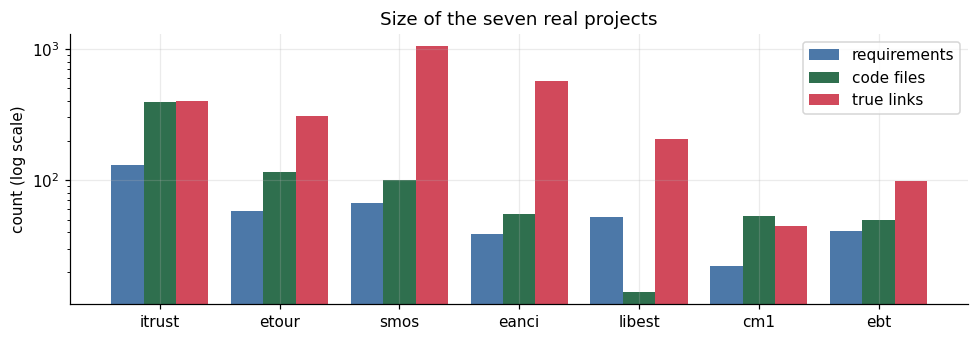

In [4]:
import json
from shared.schemas.traceability import Artifact
PROCESSED = ROOT / 'data' / 'processed'

def load(name):
    """Requirements, code files and the expert-labelled links (as index sets) of one project."""
    arts = [Artifact(**a) for a in json.loads((PROCESSED / name / 'artifacts.json').read_text(encoding='utf-8'))]
    traces = json.loads((PROCESSED / name / 'traces.json').read_text(encoding='utf-8'))
    reqs, code = [a for a in arts if a.type == 'requirement'], [a for a in arts if a.type != 'requirement']
    r_idx, c_idx = {a.id: i for i, a in enumerate(reqs)}, {a.id: i for i, a in enumerate(code)}
    gold = {}
    for t in traces:
        if t['source_id'] in r_idx and t['target_id'] in c_idx: gold.setdefault(r_idx[t['source_id']], set()).add(c_idx[t['target_id']])
    return reqs, code, gold

sizes = {}
for p in PROJECTS:
    r, c, g = load(p); sizes[p] = (len(r), len(c), sum(len(v) for v in g.values()))
    print(f'{p:7s} {len(r):4d} requirements   {len(c):4d} code files   {sizes[p][2]:5d} true links')
x = np.arange(len(PROJECTS)); fig, ax = plt.subplots(figsize=(9, 3.2))
for j, (label, c) in enumerate((('requirements', '#4c78a8'), ('code files', '#2f6f4e'), ('true links', '#d1495b'))):
    ax.bar(x + (j - 1) * 0.27, [sizes[p][j] for p in PROJECTS], 0.27, color=c, label=label)
ax.set_xticks(x); ax.set_xticklabels(PROJECTS); ax.set_yscale('log'); ax.set_ylabel('count (log scale)'); ax.set_title('Size of the seven real projects'); ax.legend(); plt.tight_layout(); plt.show()

## 4. Get the model file

Downloads only `t_bert.pt` (the size is printed first) and the model card (`README.md`), and prints the model card so you can read what the authors say about the model.

In [5]:
from huggingface_hub import HfApi, hf_hub_download
if TBERT_LOCAL:
    tbert_path = Path(TBERT_LOCAL)
else:
    info = HfApi().model_info(TBERT_REPO, files_metadata=True)
    print({s.rfilename: f'{(s.size or 0) / 1e6:.0f} MB' for s in info.siblings})
    print('licence tag:', [t for t in info.tags if t.startswith('license')], '| tags:', info.tags)
    print('\n----- model card -----\n' + Path(hf_hub_download(TBERT_REPO, 'README.md')).read_text(encoding='utf-8')[:3000] + '\n----------------------')
    tbert_path = Path(hf_hub_download(TBERT_REPO, TBERT_FILE))
print('model file:', tbert_path, f'({tbert_path.stat().st_size / 1e6:.0f} MB)')

/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/habbglobal/Desktop/J26-SE-327/project/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'.gitattributes': '0 MB', 'README.md': '0 MB', 'optimizer.pt': '997 MB', 'scheduler.pt': '0 MB', 't_bert.pt': '501 MB', 'training_args.bin': '0 MB'}
licence tag: ['license:mit'] | tags: ['TraceBERT', 'en', 'code', 'dataset:code_search_net', 'license:mit', 'region:us']

----- model card -----
---
license: mit
datasets:
- code_search_net
language:
- en
- code
library_name: TraceBERT
---
# Model Information

<!-- Provide a quick summary of what the model is/does. -->

This model is a Java-only version of the [CodeBERT-model](https://huggingface.co/microsoft/codebert-base), trained using the [TraceBERT library](https://github.com/jinfenglin/TraceBERT).

We initialized the model with the original CodeBERT-base and then again trained only on the Java part of the dataset.

The model was used for predicting trace links between software architecture documentation and Java source code on [traceability link recovery benchmarks](https://github.com/ArDoCo/Benchmark).

### Training Data

<!-- This 

Cancellation requested; stopping current tasks.


KeyboardInterrupt: 

## 5. Look inside the file (safely)

`weights_only=True` means only tensors are read; if the file contains anything else (code, custom classes) loading fails and the notebook stops with a clear message. Then the layer names are printed and matched to CodeBERT's layers: the model is only used if almost every layer matches in name **and** shape.

In [ ]:
try:
    obj = torch.load(tbert_path, map_location='cpu', weights_only=True)
except Exception as exc:
    if not ALLOW_UNSAFE_PICKLE:
        raise RuntimeError('The file is not a plain set of tensors, so it was NOT loaded (it could contain code). '
                           f'Reason: {type(exc).__name__}: {str(exc)[:200]}. Set ALLOW_UNSAFE_PICKLE = True only if you accept that risk.') from None
    obj = torch.load(tbert_path, map_location='cpu', weights_only=False)
if not isinstance(obj, dict): raise RuntimeError(f'Expected a dict of weights, got {type(obj).__name__}.')
for key in ('state_dict', 'model_state_dict', 'model'):
    if key in obj and isinstance(obj[key], dict): obj = obj[key]; break
state = {k: v for k, v in obj.items() if hasattr(v, 'shape')}
print(len(state), 'tensors;', f'{sum(v.numel() for v in state.values()) / 1e6:.0f} M parameters;', 'first layer names:'); print(*list(state)[:6], sep='\n  ')

from transformers import AutoModel, AutoTokenizer
tok = AutoTokenizer.from_pretrained(BASE); base_model = AutoModel.from_pretrained(BASE); target = base_model.state_dict()
anchor = 'embeddings.word_embeddings.weight'
prefixes = [k[:-len(anchor)] for k in state if k.endswith(anchor)]
print('encoders found in the file (prefix of the embedding layer):', prefixes)
if not prefixes: raise RuntimeError('No CodeBERT-style embedding layer was found in the file, so the weights cannot be mapped.')
PREFIX = prefixes[0]
mapped = {k[len(PREFIX):]: v for k, v in state.items() if k.startswith(PREFIX) and k[len(PREFIX):] in target and target[k[len(PREFIX):]].shape == v.shape}
share = len(mapped) / len(target)
print(f"using prefix {PREFIX!r}: {len(mapped)} of {len(target)} CodeBERT tensors found with the same name and shape ({share:.0%})")
if share < 0.9: raise RuntimeError('Less than 90% of the layers match CodeBERT, so this file is not a plain CodeBERT encoder; stopping instead of guessing.')

## 6. Make the model usable by stage 1

`PoolEncoder` turns texts into unit vectors with the chosen pooling. `BertEmbedder` gives it the `embed_batch` interface stage 1 expects, so the test uses the pipeline's own `embedding_matrix`, not a copy. A quick sanity check follows: the weights really differ from plain CodeBERT (if they did not, nothing was loaded).

In [ ]:
from agents.traceability_agent.preprocess import retrieval_text
from agents.traceability_agent.retrieval import embedding_matrix, tfidf_matrix, zscore_fuse
from shared.embeddings.embedder import Embedder

model = AutoModel.from_pretrained(BASE); missing = model.load_state_dict(mapped, strict=False); model.to(DEVICE).eval()
sample = list(mapped)[::10]                                   # every 10th layer: a spread over the whole network
changed = sum(not torch.equal(mapped[k], target[k]) for k in sample)
print('layers not loaded (missing):', len(missing.missing_keys), f'| of {len(sample)} sampled layers, {changed} differ from plain CodeBERT')
if changed == 0: print('WARNING: the weights are identical to plain CodeBERT, so this file adds nothing; the numbers below are plain CodeBERT.')

class PoolEncoder:
    def __init__(self, model, pooling): self.model, self.pooling = model, pooling
    def encode(self, texts, max_len, batch=32):
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), batch):
                enc = tok(texts[i:i + batch], padding=True, truncation=True, max_length=max_len, return_tensors='pt').to(DEVICE)
                h = self.model(**enc).last_hidden_state
                if self.pooling == 'cls': v = h[:, 0]
                else:
                    m = enc['attention_mask'].unsqueeze(-1).to(h.dtype); v = (h * m).sum(1) / m.sum(1).clamp(min=1)
                out.append(torch.nn.functional.normalize(v, dim=-1).cpu().numpy())
        return np.concatenate(out)
class BertEmbedder:
    def __init__(self, enc): self.enc = enc
    def embed_batch(self, texts): return self.enc.encode(texts, MAX_LEN).tolist() if texts else []

### Metrics

* **recall@k**: of *all* true links of the project, how many are among the k best-ranked files of their requirement (pooled over the project).
* **hit@k**: the share of requirements that have at least one true link in their top k.
* **MRR**: the mean of 1 / (rank of the first true link).
* **Bootstrap**: to know whether a difference is real, the requirements are resampled 2000 times and the number of extra true links found in the top k is recomputed each time. If the 95% interval stays above 0, the improvement is supported; if it contains 0, it could be luck.

In [ ]:
KS = (1, 3, 5, 10, 20)
def ranks_of_truth(matrix, gold):
    out = {}
    for i, truth in gold.items():
        position = {int(c): r + 1 for r, c in enumerate(np.argsort(-matrix[i], kind='stable'))}; out[i] = sorted(position[t] for t in truth)
    return out
def summarize(ranks):
    total = sum(len(r) for r in ranks.values())
    out = {f'recall@{k}': sum(sum(x <= k for x in r) for r in ranks.values()) / total for k in KS}
    out.update({f'hit@{k}': float(np.mean([r[0] <= k for r in ranks.values()])) for k in (1, 3, 5, 10)}); out['MRR'] = float(np.mean([1 / r[0] for r in ranks.values()])); return out
def bootstrap(a, b, k, n=2000):
    ids = sorted(a); diff = np.array([sum(x <= k for x in b[i]) - sum(x <= k for x in a[i]) for i in ids], dtype=float); rng = np.random.default_rng(SEED)
    means = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n)]
    return float(diff.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

## 7. Run stage 1 on every project

For each project the signals are: **TF-IDF**, **MiniLM**, **T-BERT** (one column per pooling) and, if present, our own fine-tuned **CodeBERT**. They are fused exactly as in the pipeline (z-score per requirement, equal weights): **before** = TF-IDF + MiniLM, **+ T-BERT** = before plus the T-BERT signal. No project is used to tune anything, so nothing here is selected on the test data except the choice between the two poolings, which is why both are shown.

In [ ]:
mini = Embedder('all-MiniLM-L6-v2'); reference = Embedder(str(REFERENCE_MODEL)) if REFERENCE_MODEL else None
BEFORE = 'TF-IDF + MiniLM (before)'
def run_project(name):
    reqs, code, gold = load(name); t0 = time.time()
    tf = tfidf_matrix(reqs, code, retrieval_text, CHUNK_WORDS); e_mini = embedding_matrix(reqs, code, mini, retrieval_text, CHUNK_WORDS)
    methods = {'TF-IDF': tf, 'MiniLM': e_mini, BEFORE: zscore_fuse([tf, e_mini])}
    for pool in POOLINGS:
        e_t = embedding_matrix(reqs, code, BertEmbedder(PoolEncoder(model, pool)), retrieval_text, CHUNK_WORDS)
        methods[f'T-BERT ({pool}) alone'] = e_t; methods[f'TF-IDF + MiniLM + T-BERT ({pool})'] = zscore_fuse([tf, e_mini, e_t])
    if reference is not None:
        e_ref = embedding_matrix(reqs, code, reference, retrieval_text, CHUNK_WORDS)
        methods['TF-IDF + MiniLM + our CodeBERT'] = zscore_fuse([tf, e_mini, e_ref])
    ranks = {m: ranks_of_truth(x, gold) for m, x in methods.items()}
    table = {m: summarize(r) for m, r in ranks.items()}
    boot = {m: {f'top-{k}': dict(zip(('mean', 'lo', 'hi'), bootstrap(ranks[BEFORE], ranks[m], k))) for k in (5, 10)} for m in methods if m.startswith('TF-IDF + MiniLM +')}
    print(f'  {name}: done in {time.time() - t0:.0f} s'); return {'table': table, 'bootstrap': boot, 'true_links': sum(len(v) for v in gold.values())}
results = globals().get('results', {})
for p in PROJECTS:
    if p not in results: results[p] = run_project(p)
print('finished:', list(results))

## 8. Results

### Table per project
recall@5 / recall@10 / recall@20 (true links found), hit@3 (requirements with a true link in the top 3) and MRR.

In [ ]:
cols = ['recall@5', 'recall@10', 'recall@20', 'hit@3', 'MRR']
for p, f in results.items():
    print(f"\n{p}  ({f['true_links']} true links)"); show_table(f['table'], cols)

### Average over the projects
Each project counts once, so a big project cannot dominate. This is the headline table.

In [ ]:
methods = list(next(iter(results.values()))['table'])
mean = {m: {c: float(np.mean([f['table'][m][c] for f in results.values()])) for c in cols} for m in methods}
print(f'average over {len(results)} projects'); show_table(mean, cols)

### Graph 1: recall@10, project by project
The pipeline today (TF-IDF + MiniLM) against the same plus the T-BERT signal (both poolings).

In [ ]:
ps = list(results); x = np.arange(len(ps)); fused = [m for m in methods if m.startswith('TF-IDF + MiniLM +')]; w = 0.8 / (len(fused) + 1)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - 0.4 + w / 2, [results[p]['table'][BEFORE]['recall@10'] for p in ps], w, color=color('TF-IDF + MiniLM'), label='TF-IDF + MiniLM (today)')
for j, m in enumerate(fused, start=1): ax.bar(x - 0.4 + w / 2 + j * w, [results[p]['table'][m]['recall@10'] for p in ps], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(ps); ax.set_ylabel('recall@10'); ax.set_ylim(0, 1.1); ax.legend(fontsize=7, loc='lower left'); ax.set_title('recall@10 per project'); plt.tight_layout(); plt.show()

### Graph 2: how deep do you have to look?
Average recall at the top 1, 3, 5, 10, 20 files of every requirement. A higher curve finds the true links earlier.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for m in methods:
    ax.plot(KS, [np.mean([f['table'][m][f'recall@{k}'] for f in results.values()]) for k in KS], marker='o', label=m, linestyle='--' if 'alone' in m or m in ('TF-IDF', 'MiniLM') else '-')
ax.set_xscale('log'); ax.set_xticks(KS); ax.set_xticklabels([str(k) for k in KS]); ax.set_xlabel('k (files looked at per requirement)'); ax.set_ylabel('average recall@k'); ax.legend(fontsize=6); ax.set_title('Recall by depth, averaged over the projects'); plt.tight_layout(); plt.show()

### Graph 3: is the difference real? (bootstrap)
For each project and each T-BERT pooling: how many *extra* true links per requirement the fused ranking finds in the top 10 compared with today, with a 95% interval. A bar that stays right of zero is a supported gain; a bar crossing zero cannot be told from luck.

In [ ]:
fig, axes = plt.subplots(1, len(fused), figsize=(5.5 * len(fused), 3.4), sharey=True, squeeze=False)
for ax, m in zip(axes[0], fused):
    for i, p in enumerate(ps):
        bt = results[p]['bootstrap'][m]['top-10']; ok = bt['lo'] > 0
        ax.errorbar(bt['mean'], i, xerr=[[bt['mean'] - bt['lo']], [bt['hi'] - bt['mean']]], fmt='o', color='#2f6f4e' if ok else '#b3261e' if bt['hi'] < 0 else '#6b7280', capsize=3)
    ax.axvline(0, color='black', lw=1); ax.set_yticks(range(len(ps))); ax.set_yticklabels(ps); ax.set_title(m, fontsize=8); ax.set_xlabel('extra true links per requirement (top 10)')
axes[0][0].invert_yaxis(); plt.tight_layout(); plt.show()

## 9. Verdict (written by the notebook from its own numbers)

In [ ]:
b = mean[BEFORE]
for m in fused:
    a = mean[m]; wins = [p for p in ps if results[p]['table'][m]['recall@10'] > results[p]['table'][BEFORE]['recall@10']]
    loss = [p for p in ps if results[p]['table'][m]['recall@10'] < results[p]['table'][BEFORE]['recall@10']]
    supported = [p for p in ps if results[p]['bootstrap'][m]['top-10']['lo'] > 0]
    print(f"{m}\n  average recall@10: {b['recall@10']:.3f} -> {a['recall@10']:.3f} | MRR: {b['MRR']:.3f} -> {a['MRR']:.3f}")
    print(f'  better in {len(wins)} of {len(ps)} projects {wins}; worse in {len(loss)} {loss}; supported gain in {len(supported)} {supported}')
    if len(supported) >= len(ps) // 2 + 1: print('  CONCLUSION: a supported improvement (check the leakage note before relying on it).')
    elif a['recall@10'] > b['recall@10'] and wins: print('  CONCLUSION: a small average gain that is not supported project by project: possible, unproven.')
    else: print('  CONCLUSION: no improvement of stage 1 on these projects.')

## 10. Save the results

In [ ]:
res = (Path('/content/out') if IN_COLAB else ROOT / 'data' / 'results') / 'tbert_stage1.json'; res.parent.mkdir(parents=True, exist_ok=True)
res.write_text(json.dumps({'config': {'model': f'{TBERT_REPO}/{TBERT_FILE}', 'base': BASE, 'poolings': list(POOLINGS), 'projects': PROJECTS, 'chunk_words': CHUNK_WORDS,
                                      'max_len': MAX_LEN, 'quick': QUICK, 'tensors_matched': f'{len(mapped)}/{len(target)}'},
                           'mean_over_projects': mean, 'projects': results}, indent=1))
print('saved', res)
if IN_COLAB:
    from google.colab import files; files.download(str(res))

## What to say about this notebook

* T-BERT is the published traceability model that our own fine-tuned CodeBERT resembles. The authors' original weights are no longer downloadable, so a copy published by another research group (MIT licence) was tested instead; the notebook checks what is inside the file and stops if it is not a plain CodeBERT encoder.
* It is used **only as an additional stage-1 signal, with no training**, on the same seven real projects and with the same metrics and bootstrap as the other stage-1 experiments.
* Limit to state: the model card does not say which data it was fine-tuned on beyond the `code_search_net` tag, so possible overlap with the test projects cannot be excluded; both poolings are reported because the card does not say which one the model expects.